In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)
print("PS-11 notebook is ready!")

TensorFlow version: 2.21.0
GPU available: False
PS-11 notebook is ready!


In [2]:
from google.colab import files

uploaded = files.upload()

Saving archive (1).zip to archive (1).zip


In [3]:
import os
import zipfile

zip_files = [f for f in os.listdir('/content') if f.lower().endswith('.zip')]
print("ZIP files found:", zip_files)

ZIP files found: ['archive (1).zip']


In [4]:
import os
import zipfile

zip_files = [f for f in os.listdir('/content') if f.lower().endswith('.zip')]

if not zip_files:
    print("ZIP file not found. Please check the previous upload cell.")
else:
    zip_path = os.path.join('/content', zip_files[0])
    extract_dir = '/content/rice_dataset'

    os.makedirs(extract_dir, exist_ok=True)

    with zipfile.ZipFile(zip_path, 'r') as z:
        print("Total files:", len(z.namelist()))
        z.extractall(extract_dir)

    print("Extraction completed!")
    print("Dataset location:", extract_dir)
    print("Top-level contents:", os.listdir(extract_dir)[:20])

Total files: 75001
Extraction completed!
Dataset location: /content/rice_dataset
Top-level contents: ['Rice_Image_Dataset']


In [6]:
import os

extract_dir = "/content/rice_dataset"
classes = ["Arborio", "Basmati", "Ipsala", "Jasmine", "Karacadag"]

for root, dirs, files in os.walk(extract_dir):
    found = [c for c in classes if c in dirs]
    if len(found) == 5:
        data_dir = root
        break
else:
    data_dir = None

if data_dir:
    print("Dataset path:", data_dir)
    for c in classes:
        folder = os.path.join(data_dir, c)
        print(c, ":", len(os.listdir(folder)), "items")
else:
    print("All five folders not found together.")
    print("Top-level contents:", os.listdir(extract_dir)[:30])


Dataset path: /content/rice_dataset/Rice_Image_Dataset
Arborio : 15000 items
Basmati : 15000 items
Ipsala : 15000 items
Jasmine : 15000 items
Karacadag : 15000 items


In [7]:
import os
import random
import numpy as np
from PIL import Image
from sklearn.model_selection import train_test_split

classes = ["Arborio", "Basmati", "Ipsala", "Jasmine", "Karacadag"]
data_dir = "/content/rice_dataset/Rice_Image_Dataset"

X, y = [], []
random.seed(42)

for label, name in enumerate(classes):
    folder = os.path.join(data_dir, name)
    images = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]
    selected = random.sample(images, min(200, len(images)))

    for file in selected:
        try:
            img = Image.open(os.path.join(folder, file)).convert("RGB")
            img = img.resize((96, 96))
            X.append(np.array(img))
            y.append(label)
        except Exception:
            pass

X = np.array(X, dtype=np.float32) / 255.0
y = np.array(y)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print("Images loaded:", len(X))
print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))
print("Classes:", classes)

Images loaded: 1000
Training: 700
Validation: 150
Testing: 150
Classes: ['Arborio', 'Basmati', 'Ipsala', 'Jasmine', 'Karacadag']


In [8]:
import tensorflow as tf
from tensorflow.keras import layers, models

print("TensorFlow:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)

model = models.Sequential([
    layers.Input(shape=(96, 96, 3)),
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation="relu"),
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(5, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=5,
    batch_size=32,
    verbose=1
)

TensorFlow: 2.21.0
GPU available: False
Epoch 1/5
22/22 ━━━━━━━━━━━━━━━━━━━━ 9s 368ms/step - accuracy: 0.1986 - loss: 1.5824 - val_accuracy: 0.2000 - val_loss: 1.5524
Epoch 2/5
22/22 ━━━━━━━━━━━━━━━━━━━━ 8s 358ms/step - accuracy: 0.2343 - loss: 1.5534 - val_accuracy: 0.2000 - val_loss: 1.5173
Epoch 3/5
22/22 ━━━━━━━━━━━━━━━━━━━━ 10s 327ms/step - accuracy: 0.2729 - loss: 1.4768 - val_accuracy: 0.4467 - val_loss: 1.3556
Epoch 4/5
22/22 ━━━━━━━━━━━━━━━━━━━━ 10s 318ms/step - accuracy: 0.4371 - loss: 1.2525 - val_accuracy: 0.5133 - val_loss: 1.1485
Epoch 5/5
22/22 ━━━━━━━━━━━━━━━━━━━━ 8s 355ms/step - accuracy: 0.4371 - loss: 1.2005 - val_accuracy: 0.6533 - val_loss: 1.0536


Test Accuracy: 64.00%
Macro F1 Score: 0.6160

Classification Report:
              precision    recall  f1-score   support

     Arborio       0.60      0.30      0.40        30
     Basmati       0.51      0.60      0.55        30
      Ipsala       0.86      1.00      0.92        30
     Jasmine       1.00      0.37      0.54        30
   Karacadag       0.52      0.93      0.67        30

    accuracy                           0.64       150
   macro avg       0.70      0.64      0.62       150
weighted avg       0.70      0.64      0.62       150



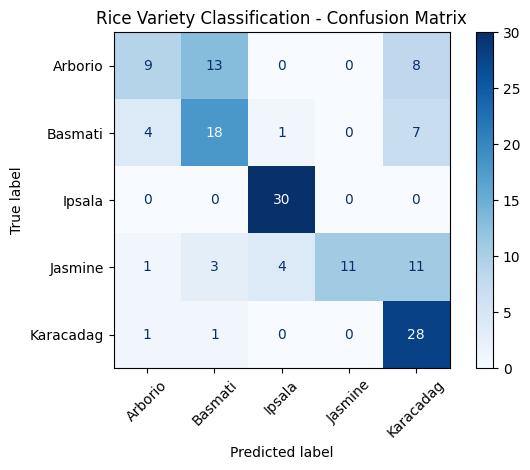

In [9]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)
import matplotlib.pyplot as plt
import numpy as np

# Evaluate on unseen test images
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)

y_prob = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print(f"Test Accuracy: {test_acc * 100:.2f}%")
print(f"Macro F1 Score: {f1_score(y_test, y_pred, average='macro'):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=classes,
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2, 3, 4])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)
disp.plot(xticks_rotation=45, cmap="Blues")
plt.title("Rice Variety Classification - Confusion Matrix")
plt.tight_layout()
plt.show()

In [10]:
import os
import json
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

os.makedirs("/content/rice_submission", exist_ok=True)

# Save trained model
model.save("/content/rice_submission/rice_classifier.keras")

# Save classification report
report = classification_report(
    y_test,
    y_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=classes,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).transpose().to_csv(
    "/content/rice_submission/classification_report.csv"
)

# Save confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2, 3, 4])
pd.DataFrame(cm, index=classes, columns=classes).to_csv(
    "/content/rice_submission/confusion_matrix.csv"
)

# Save summary metrics
with open("/content/rice_submission/summary.json", "w") as f:
    json.dump({
        "test_accuracy": float(test_acc),
        "macro_f1": float(f1_score(y_test, y_pred, average="macro")),
        "classes": classes,
        "training_images": int(len(X_train)),
        "validation_images": int(len(X_val)),
        "test_images": int(len(X_test))
    }, f, indent=4)

print("Saved model and evaluation results!")

Saved model and evaluation results!


In [11]:
import shutil
from google.colab import files

shutil.make_archive(
    "/content/rice_submission",
    "zip",
    "/content/rice_submission"
)

files.download("/content/rice_submission.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
!pip -q install gradio

import gradio as gr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from sklearn.metrics import classification_report, confusion_matrix

# Create evaluation report
report = classification_report(
    y_test,
    y_pred,
    labels=list(range(len(classes))),
    target_names=classes,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose().round(3)

# Create confusion matrix figure
cm = confusion_matrix(
    y_test, y_pred, labels=list(range(len(classes)))
)

def predict_rice(image):
    if image is None:
        return {}, "Please upload a rice image."

    image = image.convert("RGB").resize((96, 96))
    arr = np.array(image, dtype=np.float32) / 255.0
    arr = np.expand_dims(arr, axis=0)

    probabilities = model.predict(arr, verbose=0)[0]
    results = {
        classes[i]: float(probabilities[i])
        for i in range(len(classes))
    }

    best = classes[int(np.argmax(probabilities))]
    confidence = float(np.max(probabilities)) * 100

    return results, f"**Prediction:** {best}\n\n**Confidence:** {confidence:.2f}%"

def get_confusion_plot():
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.imshow(cm)
    ax.set(
        xticks=range(len(classes)),
        yticks=range(len(classes)),
        xticklabels=classes,
        yticklabels=classes,
        xlabel="Predicted variety",
        ylabel="Actual variety",
        title="Test Confusion Matrix"
    )
    plt.setp(ax.get_xticklabels(), rotation=40, ha="right")

    for i in range(len(classes)):
        for j in range(len(classes)):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center")

    fig.tight_layout()
    return fig

with gr.Blocks(title="Rice Grain Variety Classification") as app:
    gr.Markdown("# Rice Grain Variety Classification")
    gr.Markdown(
        "Upload a rice grain image to predict its variety. "
        "The model recognizes Arborio, Basmati, Ipsala, Jasmine and Karacadag."
    )

    with gr.Row():
        image_input = gr.Image(type="pil", label="Upload rice image")
        prediction_output = gr.Label(
            num_top_classes=5, label="Prediction probabilities"
        )

    result_text = gr.Markdown()
    predict_button = gr.Button("Classify Rice", variant="primary")

    predict_button.click(
        fn=predict_rice,
        inputs=image_input,
        outputs=[prediction_output, result_text]
    )

    gr.Markdown("## Model Evaluation")
    gr.Markdown(
        f"- **Test accuracy:** {test_acc * 100:.2f}%\n"
        f"- **Macro F1-score:** {f1_score(y_test, y_pred, average='macro'):.4f}\n"
        f"- **Test images:** {len(y_test)}\n"
        f"- **Training images:** {len(y_train)}"
    )

    gr.Markdown("## Classification Report")
    gr.Dataframe(value=report_df, label="Precision, recall and F1-score")

    gr.Markdown("## Confusion Matrix")
    gr.Plot(value=get_confusion_plot())

app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://8cfaf1c46220fc08d9.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
